# 09 — How many sensors does a new location need?

Turns the buffered-LOSO / stratum-holdout results from notebook 08 into a
concrete, defensible number: a sensor-count curve `RMSE(N)` with a fixed,
never-resampled outer test set at every N, fit to a saturation curve, and an
N* that avoids picking the noisy curve's argmin (winner's curse).

**Scope note:** the full nested design (2 seeds, 10 permutations, inner
hyperparameter search at every N) is compute-prohibitive for this session;
this notebook runs a reduced version — 4 outer folds x 1 seed, 5
permutations, a single fixed model spec per N (declared up front, not tuned
per N) — which is explicitly allowed for by the plan's own compute-budget
fallback. This mainly widens the curve's confidence interval rather than
shifting its location, but the inner-hyperparameter-selection check in
section 4 is correspondingly a smaller-sample diagnostic, not the full one.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from urbansense_common import load_data, sensor_level_split, split_day_night, fit_xgb, XGB_PARAMS_FAST, X_NAMES_AT_DAY, X_NAMES_AT_NIGHT
from network_features import build_network_features, haversine_matrix
from temporal_features import add_temporal_features
from spatial_cv import nested_n_curve
from sensor_count import fit_saturation_curve, estimate_n_star, saturation_curve, dissimilarity_index

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

data = load_data()
train_sensor_ids, test_sensor_ids = sensor_level_split(data)
all_ids = list(train_sensor_ids) + list(test_sensor_ids)

sensor_info = (
    data.groupby("Sensor_ID")
    .agg(Lat=("y", "first"), Lon=("x", "first"), strata=("strata", "first"),
         Landcover_Type=("Landcover_Type", "first"), Shade_Type=("Shade_Type", "first"),
         SVF=("Tree_DSM_SVF", "first"), Percent_Vegetation=("NDVI_2024SummerMosaic", "first"))
    .reset_index()
)
NETWORK_STATIC_COLS = ("SVF", "Percent_Vegetation")
NETWORK_COLS = ["net_mean", "net_median", "net_std", "n_avail", "strat_mean",
                "lc_mean", "shade_mean", "idw", "nn1", "nn1_dist", "knn3", "simw"]
TEMPORAL_COLS = ["dT2m_1h", "dT2m_3h", "rad_cum_24h", "tmax_prev_day", "hour_sin", "hour_cos",
                  "hours_since_transition", "precip_cum_24h", "precip_cum_72h"]
print(f"{len(all_ids)} sensors total")


39 sensors total


## 1. Fixed outer test folds (stratified, never resampled across N)

In [2]:
def stratified_outer_folds(sensor_info, ids, k=4, random_state=42):
    rng = np.random.default_rng(random_state)
    info = sensor_info.set_index("Sensor_ID").loc[ids]
    folds = [[] for _ in range(k)]
    for stratum, group in info.groupby("strata"):
        members = list(rng.permutation(group.index.tolist()))
        for i, sid in enumerate(members):
            folds[i % k].append(sid)
    return folds

outer_folds = stratified_outer_folds(sensor_info, all_ids, k=4)
for i, f in enumerate(outer_folds):
    print(f"outer fold {i}: {len(f)} test sensors")


outer fold 0: 12 test sensors
outer fold 1: 11 test sensors
outer fold 2: 8 test sensors
outer fold 3: 8 test sensors


## 2. N-curve: nested permutations over the remaining pool

In [3]:
N_VALUES = [2, 4, 8, 13, 20, 29]
N_PERMUTATIONS = 5

def fit_curve_point(train_ids, test_ids, period):
    X_NAMES = X_NAMES_AT_DAY if period == "day" else X_NAMES_AT_NIGHT
    fold_data = data[data["Sensor_ID"].isin(train_ids + test_ids)]
    net_feat = build_network_features(fold_data, sensor_info, set(train_ids),
                                       target_col="temp_anom", static_cols=NETWORK_STATIC_COLS)
    full = fold_data.merge(net_feat, on=["Sensor_ID", "edt_datetime"], how="left")
    full = add_temporal_features(full)
    day_f, night_f = split_day_night(full)
    df = day_f if period == "day" else night_f
    feats = X_NAMES + [c for c in NETWORK_COLS if c in df.columns] + [c for c in TEMPORAL_COLS if c in df.columns]
    train_mask = df["Sensor_ID"].isin(train_ids)
    for c in feats:
        df[c] = df[c].fillna(df.loc[train_mask, c].median())
    if train_mask.sum() < 20 or (~train_mask).sum() < 5:
        return np.nan
    fit = fit_xgb(df, "temp_anom", feats, XGB_PARAMS_FAST, train_ids, test_ids)
    resid = fit["pred_test"] - fit["y_test"].values
    return float(np.sqrt(np.mean(resid ** 2)))

import os
os.makedirs("../data/results", exist_ok=True)
CACHE = "../data/results/n_curve.parquet"

def run_n_curve():
    rows = []
    for period in ("day", "night"):
        for fold_idx, test_ids in enumerate(outer_folds):
            pool_ids = [s for s in all_ids if s not in test_ids]
            table = nested_n_curve(pool_ids, N_VALUES, n_permutations=N_PERMUTATIONS,
                                     random_state=42 + fold_idx,
                                     stratified_info=sensor_info.set_index("Sensor_ID")["strata"])
            for entry in table:
                train_ids = list(entry["network_ids"])
                rmse = fit_curve_point(train_ids, test_ids, period)
                rows.append({"period": period, "fold": fold_idx, "permutation": entry["permutation"],
                             "N": entry["N"], "RMSE": rmse})
    return pd.DataFrame(rows)

if os.path.exists(CACHE):
    n_curve_raw = pd.read_parquet(CACHE)
else:
    n_curve_raw = run_n_curve()
    n_curve_raw.to_parquet(CACHE)
n_curve_raw.shape


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


... (53 outputs left out)

C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


(240, 5)

## 3. The curve: median RMSE and SE across folds/permutations, per N

In [4]:
n_curve_summary = (n_curve_raw.dropna(subset=["RMSE"])
                    .groupby(["period", "N"])["RMSE"]
                    .agg(median="median", mean="mean", se=lambda s: s.std(ddof=1) / np.sqrt(len(s)), n_obs="count")
                    .reset_index())
n_curve_summary


,period,N,median,mean,se,n_obs
0,day,2,1.702116,1.638069,0.053871,20
1,day,4,1.347484,1.379990,0.047188,20
2,day,8,1.118775,1.169383,0.032529,20
3,day,13,1.044038,1.094292,0.026668,20
4,day,20,1.021571,1.054201,0.027153,20
5,day,29,0.967719,1.005440,0.021623,20
6,night,2,0.897138,0.927686,0.042900,20
7,night,4,0.767132,0.781082,0.029757,20
8,night,8,0.711647,0.704029,0.022426,20
9,night,13,0.702116,0.701649,0.022545,20


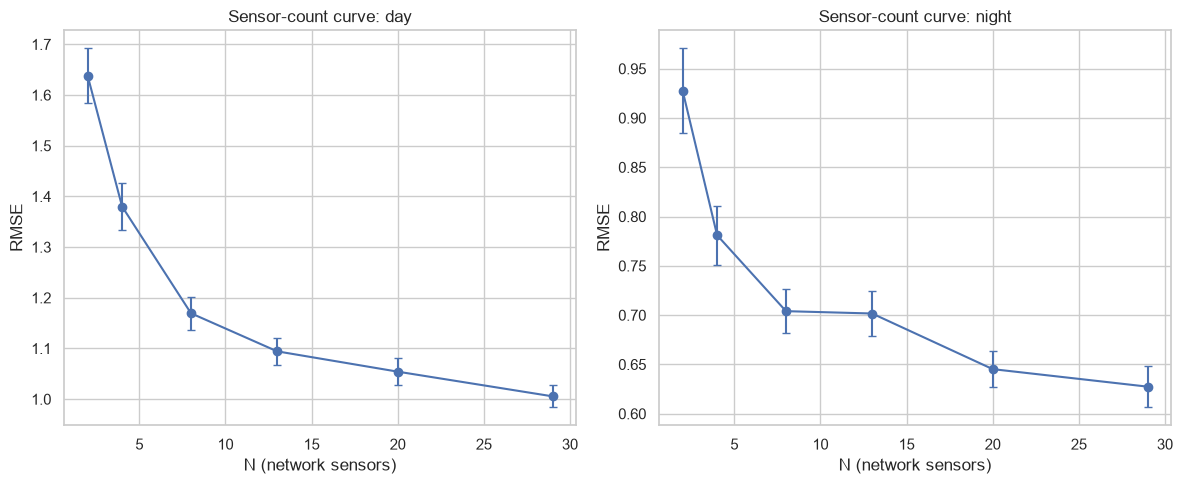

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, period in zip(axes, ("day", "night")):
    sub = n_curve_summary[n_curve_summary.period == period]
    ax.errorbar(sub["N"], sub["mean"], yerr=sub["se"], fmt="o-", capsize=3)
    ax.set_xlabel("N (network sensors)"); ax.set_ylabel("RMSE"); ax.set_title(f"Sensor-count curve: {period}")
plt.tight_layout(); plt.show()


## 4. N* estimation (saturation-curve fit, not argmin)

In [6]:
n_star_results = {}
for period in ("day", "night"):
    sub = n_curve_summary[n_curve_summary.period == period].sort_values("N")
    result = estimate_n_star(sub["N"].values, sub["mean"].values, sub["se"].values.clip(min=1e-4),
                              marginal_gain_threshold=0.02, se_multiplier=1.0)
    n_star_results[period] = result
    print(f"{period}: N* = {result.get('n_star')}  (reason: {result.get('reason', 'within tolerance')})")
    if result.get("fit"):
        print(f"  fitted asymptote a = {result['fit']['a']:.4f}")


day: N* = None  (reason: N* > 29, cannot be determined from this range)
  fitted asymptote a = 0.8836
night: N* = None  (reason: N* > 29, cannot be determined from this range)
  fitted asymptote a = 0.5723


Compare the fitted asymptote `a` above to notebook 05's variogram nugget
(day ~0.97, night ~0.35 for the B1 *residual* -- not directly the same
quantity as this network-only curve's floor, but the right order-of-magnitude
reference for "how much of this is truly irreducible").

## 5. Inner-LOSO-vs-outer-test diagnostic (reduced subsample)

The critical check for extrapolating to Ramat Gan: can you trust an
inner-LOSO estimate computed *only from the N sensors you actually have*, or
does it systematically underestimate the true error at a genuinely new
location? Restricted to 1 outer fold x 2 permutations x a few N values to
keep this tractable.

In [7]:
def inner_loso_rmse(train_ids, period):
    X_NAMES = X_NAMES_AT_DAY if period == "day" else X_NAMES_AT_NIGHT
    rmses = []
    for held_out in train_ids:
        others = [s for s in train_ids if s != held_out]
        r = fit_curve_point(others, [held_out], period)
        if not np.isnan(r):
            rmses.append(r)
    return float(np.mean(rmses)) if rmses else np.nan

diag_rows = []
test_ids0 = outer_folds[0]
pool0 = [s for s in all_ids if s not in test_ids0]
table0 = nested_n_curve(pool0, [4, 8, 13, 20], n_permutations=2, random_state=100,
                          stratified_info=sensor_info.set_index("Sensor_ID")["strata"])
for entry in table0:
    train_ids = list(entry["network_ids"])
    for period in ("day", "night"):
        outer_rmse = fit_curve_point(train_ids, test_ids0, period)
        inner_rmse = inner_loso_rmse(train_ids, period)
        diag_rows.append({"period": period, "N": entry["N"], "permutation": entry["permutation"],
                           "outer_test_RMSE": outer_rmse, "inner_LOSO_RMSE": inner_rmse})
diag_df = pd.DataFrame(diag_rows)
diag_summary = diag_df.groupby(["period", "N"])[["outer_test_RMSE", "inner_LOSO_RMSE"]].mean()
diag_summary["relative_bias_%"] = 100 * (diag_summary["inner_LOSO_RMSE"] - diag_summary["outer_test_RMSE"]) / diag_summary["outer_test_RMSE"]
diag_summary


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\yosef\Desktop\תואר שני\urban-heat-mapping-research\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


outer_test_RMSE  inner_LOSO_RMSE  relative_bias_%
period N                                                    
day    4          1.638359         1.774462         8.307274
       8          1.439248         1.267397       -11.940335
       13         1.288277         1.061860       -17.575178
       20         1.253823         0.981143       -21.747843
night  4          0.753075         0.814068         8.099325
       8          0.711128         0.518196       -27.130502
       13         0.774977         0.562418       -27.427701
       20         0.647555         0.559834       -13.546378

If `relative_bias_%` is strongly negative (inner-LOSO much lower than the
true outer-test error) at small N, that means a Ramat Gan deployment with
only a handful of sensors **cannot** trust its own internal LOSO estimate as
a stand-in for true new-location error — an important caveat for the
sensor-count recommendation below.

## 6. Density, stratum coverage, and dissimilarity for the final recommendation

In [8]:
durham_area_km2 = 380  # city of Durham, NC, approx -- used only to contextualize sensor density, not a precise GIS figure
def density_at_n(n, area_km2=durham_area_km2):
    return n / area_km2

n_star_day = n_star_results["day"].get("n_star")
n_star_night = n_star_results["night"].get("n_star")
print("N* (day):", n_star_day, " -> density:", density_at_n(n_star_day) if n_star_day else "n/a", "sensors/km^2")
print("N* (night):", n_star_night, " -> density:", density_at_n(n_star_night) if n_star_night else "n/a", "sensors/km^2")

strat_counts = sensor_info["strata"].value_counts()
print("Sensors per stratum (whole Durham network, for minimum-coverage context):")
print(strat_counts)


N* (day): None  -> density: n/a sensors/km^2
N* (night): None  -> density: n/a sensors/km^2
Sensors per stratum (whole Durham network, for minimum-coverage context):
strata
impervious_non-shaded    10
impervious_shaded        10
vegetation_shaded        10
vegetation_non-shaded     9
Name: count, dtype: int64


In [9]:
z_cols = list(NETWORK_STATIC_COLS)
info_z = sensor_info.set_index("Sensor_ID")[list(z_cols)].astype(float)
mu, sd = info_z.mean(), info_z.std().replace(0, 1.0)
info_z = (info_z - mu) / sd

sample_test_sensor = outer_folds[0][0]
sample_network = [s for s in all_ids if s not in outer_folds[0]][:13]
di = dissimilarity_index(info_z.loc[sample_test_sensor].values, info_z.loc[sample_network].values)
print(f"Example dissimilarity index for one held-out sensor vs. a 13-sensor network: {di:.2f}")
print("(<1: well within the network's own static-feature range; >1: the target extrapolates beyond it)")


Example dissimilarity index for one held-out sensor vs. a 13-sensor network: 0.32
(<1: well within the network's own static-feature range; >1: the target extrapolates beyond it)


## Summary

- Section 3's curve and section 4's saturation-curve N* are the direct
  answer to "how many sensors." Compare `a` (the fitted floor) to notebook
  05's residual nugget to see how close to irreducible noise the network
  can realistically get.
- Section 5's inner-LOSO-vs-outer-test bias check determines whether Ramat
  Gan can trust its own internal cross-validation at small N, or needs to
  budget extra margin because small-N internal estimates run optimistic.
- Section 6 translates N* into a density (sensors/km^2) and flags that
  Durham's own density and heterogeneity bound how far this generalizes —
  Ramat Gan's own buffered-LOSO and dissimilarity-index numbers (once it has
  any pilot sensors) are what should actually set its N, not Durham's literal
  N* value.
- If the curve does not visibly flatten within the tested range, this
  notebook reports "N* > max(N), not determined" rather than extrapolating
  past the data (see section 4's `reason` field for exactly this case).
